# **PROJETO SP - Encriptação de dados**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

### **Resumo**

Neste projeto, simulamos um cenário de análise de dados no contexto de telecomunicações, com especial foco em privacidade e proteção de informação sensível. O objetivo é explorar como é possível extrair valor analítico a partir de dados anonimizados, permitindo a sua utilização por uma entidade externa sem comprometer a identidade dos clientes.

Ao longo do trabalho, aplicámos diferentes técnicas de tratamento de dados, como anonimização, generalização e mascaramento de variáveis, de forma a reduzir o risco de reidentificação, mantendo a utilidade do dataset para análise. Posteriormente, realizámos uma segmentação de clientes com base em padrões de utilização, permitindo identificar diferentes perfis comportamentais.

Com este projeto pretendemos demonstrar, de forma prática, o equilíbrio entre privacidade e utilidade dos dados em contextos reais de análise e outsourcing de informação.

## **1. Imports**

In [ ]:
# Imports principais
from google.colab import files
import pandas as pd
import numpy as np
import io

# Processamento e utilitários
import re
import hashlib

# Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Visualização de dados
import matplotlib.pyplot as plt

## **2. Data Upload**

In [ ]:
# Upload do dataset (em csv)

uploaded = files.upload()

df = pd.read_csv(io.BytesIO(uploaded['telecom_dataset.csv']), sep=',')

Saving telecom_dataset.csv to telecom_dataset.csv


## **3. Dataset Original (Raw)**

In [ ]:
df.head()

,customer_id,full_name,age,gender,phone_number,email,district,call_minutes,messages,monthly_data_gb,monthly_bill_eur,contract_type
0,CUST0001,William Vieira,58,male,995822412,william.vieira@gmail.com,Porto,607,140,10,91.57,Pré-Pago
1,CUST0002,Álvaro Araújo,25,male,939958838,alvaro.araujo@gmail.com,Braga,196,786,240,21.27,Empresarial
2,CUST0003,Luca Pereira,19,female,983197857,luca.pereira@gmail.com,Porto,202,361,190,56.41,Pré-Pago
3,CUST0004,Anita Ferreira,41,female,922575562,anita.ferreira@gmail.com,Coimbra,500,364,80,65.59,Pré-Pago
4,CUST0005,Leonor Carneiro,27,male,985329037,leonor.carneiro@gmail.com,Coimbra,223,478,230,81.49,Empresarial


### **3.1. Análise ao dataset**

O dataset utilizado para o projeto contém dados gerados pelo ChatGPT com a finalidade de simulação de registos dos clientes de uma empresa de telecomunicações. Como tal, é necessária uma breve análise para verificar o *dtypes*, a presença de nulos e de linhas duplicadas, para garantir que a IA gerou um dataset de qualidade e sem necessidade de data cleaning.

In [ ]:
### ---ANÁLISE DO DATASET--- ###

print("----- ANÁLISE DO DATASET -----\n")

# Forma do dataset
print("----- Forma do dataset -----\n")
print(f"df shape:   {df.shape}\n")

# Info do dataset
print("----- Informações do dataset -----\n")
print(f" df info:   {df.info()}\n")

# Tipos de dados
print("----- Tipo de dados do dataset -----\n")
print("df dtypes:")
print(df.dtypes, "\n")

# Estatísticas descritivas
print("----- Dados descritivos do dataset -----\n")
print("df describe:")
print(df.describe(), "\n")

# Duplicados
print("----- Duplicados do dataset -----\n")
print(f"df duplicados:   {df.duplicated().sum()}\n")

# Nulos por coluna
print("----- Nulos por coluna -----\n")
print("df nulos por coluna:")
print(df.isnull().sum(), "\n")

# Total de nulos
print("----- Total de nulos -----\n")
print(f"df total de nulos:   {df.isnull().sum().sum()}")

----- ANÁLISE DO DATASET -----

----- Forma do dataset -----

df shape:   (1000, 12)

----- Informações do dataset -----

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       1000 non-null   object 
 1   full_name         1000 non-null   object 
 2   age               1000 non-null   int64  
 3   gender            1000 non-null   object 
 4   phone_number      1000 non-null   int64  
 5   email             1000 non-null   object 
 6   district          1000 non-null   object 
 7   call_minutes      1000 non-null   int64  
 8   messages          1000 non-null   int64  
 9   monthly_data_gb   1000 non-null   int64  
 10  monthly_bill_eur  1000 non-null   float64
 11  contract_type     1000 non-null   object 
dtypes: float64(1), int64(5), object(6)
memory usage: 93.9+ KB
 df info:   None

----- Tipo de dados do dataset --

A análise inicial revela que o dataset é composto por **1.000 observações** e **12 variáveis**. Estas incluem identificadores diretos (`'customer_id'`, `'full_name'`, `'phone_number'`, `'email'`), dados demográficos (`'age'`, `'gender'`, `'district'`) e métricas de consumo e faturação do serviço de telecomunicações (`'call_minutes'`, `'messages'`, `'monthly_data_gb'`, `'monthly_bill_eur'` e `'contract_type'`).

Relativamente aos tipos de dados, as variáveis de identificação e categóricas (como `'gender'`, `'district'` e `'contract_type'`) estão definidas como ***object***, enquanto as métricas de utilização e a `'age'` são representadas por ***int64*** e ***float64***. Consideramos esta configuração adequada para as fases subsequentes de anonimização e clustering.

No que respeita à integridade dos dados, não foram detetados valores nulos em nenhuma das colunas analisadas, nem se registou a presença de registos duplicados. Isto confirma que o dataset simulado possui a qualidade necessária para o estudo sem exigir etapas adicionais de limpeza profunda.

A análise estatística das variáveis numéricas mostra que a faturação mensal média (`'monthly_bill_eur'`) é de aproximadamente 65,10€, variando entre os 10,17€ e os 119,83€. Observa-se também que a mediana do consumo de dados (`'monthly_data_gb'`) situa-se nos 130 GB e a de `'call_minutes'` nos 300 minutos, o que fornece uma visão clara dos padrões de utilização típicos desta amostra de clientes.

### **3.2. Classificação de sensibilidade**

| Feature          | Descrição                                 | Sensibilidade | Motivo                                  |
|------------------|-------------------------------------------|----------------|------------------------------------------|
| customer_id      | Identificador único do cliente            | Alta           | Permite identificação individual         |
| full_name        | Nome completo do cliente                  | Alta           | Identificação direta                     |
| age              | Idade do cliente                          | Média          | Pode permitir reidentificação            |
| gender           | Género do cliente                         | Baixa          | Informação demográfica genérica          |
| phone_number     | Número de telemóvel do cliente            | Alta           | Informação pessoal e identificável       |
| email            | Endereço de email do cliente              | Alta           | Identificação direta                     |
| district         | Distrito de residência do cliente         | Média          | Dados geográficos                        |
| call_minutes     | Minutos mensais de chamadas disponíveis   | Baixa          | Informação de utilização do serviço      |
| messages         | Número de mensagens incluídas no plano    | Baixa          | Informação operacional do serviço        |
| monthly_data_gb  | Pacote mensal de dados móveis (GB)       | Baixa          | Estatística de utilização                |
| monthly_bill_eur | Valor mensal pago pelo cliente (€)        | Baixa          | Estatística operacional                  |
| contract_type    | Tipo de contrato telecomunicações         | Baixa          | Informação comercial não identificável   |

## **4. Pipeline de Anonimização**

A empresa que pretende enviar os dados para uma empresa externa realizar uma análise precisa de encriptar e anonimizar parte da informação, de forma a evitar a exposição de dados sensíveis. Para simular esse processo, vamos aplicar quatro tipos de tratamento de features. Estas transformações serão aplicadas a `df_anonimo`, uma cópia de `df`, preservando assim os dados originais. A empresa externa terá acesso apenas ao dataset anonimizado (`df_anonimo`).

In [ ]:
df_anonimo = df.copy()

### **4.1. Hashing**

Usamos o hashing nesta etapa para proteger dados sensíveis dos clientes antes de enviarmos o dataset para uma empresa externa. Esta técnica transforma valores originais numa sequência de caracteres irreversível, permitindo ocultar a informação real sem perder consistência entre registos.

As colunas escolhidas para hashing foram `'customer_id'`, `'email'` e `'phone_number'`, uma vez que são identificadores diretos dos clientes e podem ser usados para reidentificação ou exposição de informação pessoal. Apesar de os valores originais deixarem de estar visíveis, ainda é possível distinguir clientes diferentes dentro do dataset anonimizado.

Também utilizámos um ***salt***, ou seja, uma sequência adicional adicionada ao valor original antes da geração do hash. Isto aumenta a segurança do processo, dificultando ataques como *brute force* ou *rainbow table attacks*, tornando muito mais difícil reconstruir os dados originais.

O objetivo desta fase não é eliminar totalmente o risco, mas sim reduzir significativamente a exposição de informação sensível, mantendo ao mesmo tempo a utilidade analítica do dataset. Segurança real é sempre um equilíbrio entre proteção e utilidade, e ignorar isso tende a transformar dados úteis num conjunto de informação tecnicamente seguro, mas analiticamente pobre.


#### **4.1.1 Aplicação do Hashing**

In [ ]:
def hash_value(value, salt="telecom2026"):
    value = str(value)
    return hashlib.sha256((value + salt).encode()).hexdigest()

In [ ]:
cols_to_hash = ["customer_id", "email", "phone_number"]

for col in cols_to_hash:
    df_anonimo[col] = df_anonimo[col].apply(hash_value)

#### **4.1.2 Criação de um dataframe de ligação**

Decidimos criar uma tabela de ligação (`bridge`) para garantir a correspondência entre o dataset original e o dataset anonimizado enviado para análise externa. Esta tabela associa o identificador original do cliente ao seu respetivo identificador em hash, permitindo que os resultados obtidos pela empresa externa (como os clusters) possam ser posteriormente reintegrados no dataset da empresa-mãe.

Desta forma, mantemos a separação entre dados sensíveis e dados analíticos, garantindo privacidade durante o processamento externo, mas preservando a capacidade de reconstruir os resultados ao nível do sistema original.


In [ ]:
bridge = df[["customer_id"]].copy()
bridge["customer_id_hash"] = bridge["customer_id"].apply(hash_value)

In [ ]:
bridge.head()

,customer_id,customer_id_hash
0,CUST0001,ba69318c143d418424eb50226a4c45071fee4f1fd330b2...
1,CUST0002,f5acf95ad64c1ac9ec6d616ea5053574b55acf1e33a8ed...
2,CUST0003,4303adfb5f1f1390f1b840477c9631a58a61e0d01e098b...
3,CUST0004,6ad56ccbdc9b4e51d85cf990ac439eab596c1a4943b931...
4,CUST0005,4bd5047c807099cebad1aeaf570e45158ac85eb72f50dc...


#### **4.1.3 Renomeação das colunas que sofreram Hashing**

In [ ]:
df_anonimo = df_anonimo.rename(columns={"customer_id": "customer_id_hash"})
df_anonimo = df_anonimo.rename(columns={"email": "email_hash"})
df_anonimo = df_anonimo.rename(columns={"phone_number": "phone_number_hash"})

### **4.2. Generalização**

Aplicámos uma técnica de generalização à coluna `'age'`, substituindo idades exatas por grupos etários. Esta abordagem reduz o risco de reidentificação dos clientes, mantendo ao mesmo tempo a utilidade analítica dos dados. Os intervalos foram definidos com base em faixas etárias representativas de diferentes padrões de utilização de serviços de telecomunicações.

In [ ]:
def age_bucket(age):
    if age <= 18:
        return "A1"
    elif age <= 34:
        return "A2"
    elif age <= 49:
        return "A3"
    elif age <= 64:
        return "A4"
    else:
        return "A5"

In [ ]:
df_anonimo["age_group"] = df_anonimo["age"].apply(age_bucket)

df_anonimo.drop(columns=["age"], inplace=True)

In [ ]:
cols = list(df_anonimo.columns)

cols.insert(cols.index("gender"), cols.pop(cols.index("age_group")))

df_anonimo = df_anonimo[cols]

In [ ]:
age_mapping = {
    "A1": "0-18",
    "A2": "19-34",
    "A3": "35-49",
    "A4": "50-64",
    "A5": "65+"
}

### **4.3. Supressão**

Foi aplicada uma técnica de supressão de dados à coluna `full_name`, uma vez que esta contém informação diretamente identificável e não contribui para a análise estatística do problema. A remoção desta variável reduz significativamente o risco de identificação dos clientes, alinhando o dataset com princípios de minimização de dados e privacidade.

In [ ]:
df_anonimo.drop(columns=["full_name"], inplace=True)

### **4.4. Mascaramento parcial**

Aplicámos uma técnica de mascaramento parcial à variável `district`, através da agregação de distritos em regiões geográficas mais amplas. Esta abordagem reduz a granularidade espacial dos dados, diminuindo o risco de reidentificação de clientes quando combinada com outras variáveis. Apesar da perda de detalhe, mantemos a utilidade do atributo para análises estatísticas a nível regional.


In [ ]:
district_map = {
    "Porto": "D1",
    "Braga": "D1",
    "Aveiro": "D2",
    "Coimbra": "D2",
    "Leiria": "D2",
    "Lisboa": "D3",
    "Setúbal": "D3",
    "Faro": "D4"
}

In [ ]:
df_anonimo["district"] = df_anonimo["district"].map(district_map)

In [ ]:
district_mapping = {
    "D1": "NORTE",
    "D2": "CENTRO",
    "D3": "AM LISBOA",
    "D4": "SUL"
}

## **5. Dataset anonimizado**

Depois da aplicação de todas as técnicas de tratamento de dados, o `df_anonimo` passou a representar uma versão protegida do dataset original, mantendo utilidade analítica sem expor informação sensível.

Foram removidos ou transformados identificadores diretos através de hashing e supressão, reduzida a granularidade de variáveis críticas como idade e localização, e preservada apenas a informação necessária para análise estatística e segmentação de clientes. O resultado é um dataset equilibrado entre privacidade e utilidade, adequado para ser partilhado com uma entidade externa para fins de análise, sem comprometer a segurança dos clientes.


In [ ]:
df_anonimo.head()

,customer_id_hash,age_group,gender,phone_number_hash,email_hash,district,call_minutes,messages,monthly_data_gb,monthly_bill_eur,contract_type
0,ba69318c143d418424eb50226a4c45071fee4f1fd330b2...,A4,male,3f837ee545f66f068e521a2213597f14433e5bd74bfdc2...,8a80df9e1ef4e1fe04eed592912288550d78ac97209c98...,D1,607,140,10,91.57,Pré-Pago
1,f5acf95ad64c1ac9ec6d616ea5053574b55acf1e33a8ed...,A2,male,99048f3e8bac2dae3837f859dc6039608e9a4bffc7c78a...,17261809966ce4d126ba7170e9d902f84ab7a1e6fcc978...,D1,196,786,240,21.27,Empresarial
2,4303adfb5f1f1390f1b840477c9631a58a61e0d01e098b...,A2,female,3b65aa3128fceea7e4442fc6c11ed5b0cc24347416f8d8...,001a42025c20bb08e11a52ba62b37a71ce1d5cba119459...,D1,202,361,190,56.41,Pré-Pago
3,6ad56ccbdc9b4e51d85cf990ac439eab596c1a4943b931...,A3,female,aeabdf9a969390d7ba46c337a2cf0933dfd76cafcefb3e...,606d435407c9261fb2610abc0f27994c048af6e35e027d...,D2,500,364,80,65.59,Pré-Pago
4,4bd5047c807099cebad1aeaf570e45158ac85eb72f50dc...,A2,male,6529ad6ba1f859eacb4ff48583c517aa75b708d61fa2b1...,4966e2e4de6e07edd5020a565a960c9cec1bd91af44337...,D2,223,478,230,81.49,Empresarial


**Nota:** o passo de transformar `df_anonimo` num csv e fazer o seu download não é necessário, já que todo o projeto é realizado no mesmo notebook. Contudo, decidimos incluir esta abordagem para efetivamente simular como duas empresas, uma com dados seus para analisar e outra que analisará esses dados, agiriam. O csv abaixo ("df_anonimo_empresa_X.csv") seria enviado pela empresa-mãe à empresa externa que iria realizar a análise.

In [ ]:
df_anonimo.to_csv("df_anonimo_empresa_X.csv", index=False)

files.download("df_anonimo_empresa_X.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **6. Análise Empresa Externa (Clustering)**

**O bloco 6 simula a atividade da empresa externa que vai realizar a análise.**

---

No início desta etapa, a empresa externa faria o upload do documento csv via, por exemplo, código comentado abaixo (a verde). Contudo, dado que toda a simulação do presente projeto está a ser feita no mesmo notebook e que, por isso, o documento em causa já se encontra na aba Ficheiros do Colab à esquerda, vamos apenas criar uma variável cópia chamada `df_analise_empresa_X`.

In [ ]:
# uploaded = files.upload()
# df_analise_empresa_X = pd.read_csv(io.BytesIO(uploaded['df_anonimo_empresa_X.csv']), sep=',')

df_analise_empresa_X = df_anonimo.copy()

O restante bloco simula a análise realizada pela empresa externa, onde são aplicadas técnicas de clustering para segmentação de clientes com base em variáveis comportamentais, demográficas e contratuais do dataset anonimizado.

### **6.1. Seleção de features para clustering**

In [ ]:
features = df_analise_empresa_X.copy()

features = df_analise_empresa_X[[
    "call_minutes",
    "messages",
    "monthly_data_gb",
    "monthly_bill_eur",
    "age_group",
    "district",
    "contract_type",
    "gender"
]]

### **6.2. Preprocessing**

#### **6.2.1. One-Hot Encoding**

In [ ]:
features_encoded = pd.get_dummies(features, drop_first=True)

#### **6.2.2. Normalização (StandardScaler)**

In [ ]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_encoded)

### **6.3. Escolha do número de clusters (Elbow Method)**

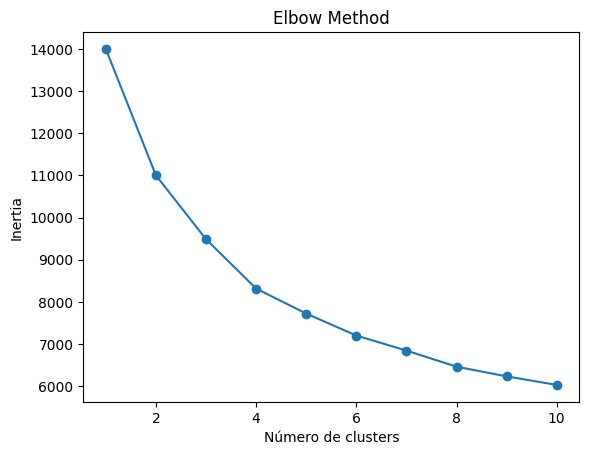

In [ ]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_features)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Número de clusters")
plt.ylabel("Inertia")
plt.show()

### **6.4. Treino do modelo**

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_analise_empresa_X["cluster"] = kmeans.fit_predict(scaled_features)

### **6.5. Análise dos clusters**

In [ ]:
df_analise_empresa_X["cluster"].value_counts()

,count
cluster,
0,471
1,252
3,191
2,86


In [ ]:
df_analise_empresa_X.groupby("cluster").mean(numeric_only=True)

,call_minutes,messages,monthly_data_gb,monthly_bill_eur
cluster,,,,
0,216.403397,579.490446,190.191083,63.778025
1,393.690476,289.337302,115.436508,68.680040
2,744.383721,119.569767,30.348837,63.281977
3,613.460733,180.371728,60.575916,64.441990


In [ ]:
df_analise_empresa_X.groupby("cluster")["age_group"].value_counts(normalize=True)

cluster  age_group
0        A2           0.942675
         A1           0.057325
1        A3           1.000000
2        A5           1.000000
3        A4           1.000000
Name: proportion, dtype: float64

In [ ]:
df_analise_empresa_X.groupby("cluster")["district"].value_counts(normalize=True)

cluster  district
0        D2          0.341826
         D1          0.307856
         D3          0.256900
         D4          0.093418
1        D2          0.369048
         D3          0.293651
         D1          0.242063
         D4          0.095238
2        D2          0.395349
         D3          0.255814
         D1          0.244186
         D4          0.104651
3        D2          0.424084
         D3          0.272251
         D1          0.188482
         D4          0.115183
Name: proportion, dtype: float64

In [ ]:
df_analise_empresa_X.groupby("cluster")["contract_type"].value_counts(normalize=True)

cluster  contract_type
0        Empresarial      0.346072
         Pós-Pago         0.333333
         Pré-Pago         0.320594
1        Pré-Pago         0.361111
         Pós-Pago         0.325397
         Empresarial      0.313492
2        Empresarial      0.383721
         Pré-Pago         0.337209
         Pós-Pago         0.279070
3        Pós-Pago         0.350785
         Empresarial      0.324607
         Pré-Pago         0.324607
Name: proportion, dtype: float64

#### ***Cluster 0 -> Jovens Hiperconectados em Dados (≈47% dos clientes)***

Este cluster é o perfil dominante da amostra, representando quase metade da base de clientes. É composto maioritariamente por jovens adultos (cerca de 94% pertencem ao escalão 19-34 anos). Caracterizam-se por um consumo massivo de dados móveis (média de 190 GB) e de mensagens (579 em média), mas apresentam o menor volume de chamadas de voz (216 minutos). É um segmento que privilegia a comunicação digital e o consumo de conteúdo online, distribuindo-se de forma equilibrada entre os vários tipos de contrato.

---

#### ***Cluster 1 -> Utilizadores de Meia-Idade com Alto Valor (≈25% dos clientes)***

Este grupo agrega exclusivamente clientes na faixa etária dos 35 aos 49 anos. Apresentam um comportamento de consumo equilibrado, com uma utilização moderada de dados (115 GB) e de voz (394 minutos). Notavelmente, este é o segmento com a faturação média mais elevada (68,68€), o que indica uma elevada rentabilidade para a empresa. Existe uma ligeira preferência pelo regime Pré-pago (36%) dentro deste grupo.

---

#### ***Cluster 2 -> Séniores Focados em Voz (≈9% dos clientes)***

Este é o cluster mais pequeno e específico, composto inteiramente por clientes com 65 ou mais anos. O seu perfil de utilização é marcadamente tradicional: registam o maior consumo de minutos de voz de todo o dataset (744 minutos em média), em contraste com o menor consumo de dados (apenas 30 GB) e de mensagens. Curiosamente, este grupo apresenta uma forte incidência de contratos do tipo Empresarial (38%), sugerindo que muitos destes utilizadores ainda mantêm atividade profissional ou planos específicos de longa duração.

---

#### ***Cluster 3 -> Utilizadores Maduros em Transição Digital (≈19% dos clientes)***

Este grupo é constituído por clientes na faixa dos 50 aos 64 anos. Apresentam um volume de chamadas bastante elevado (613 minutos), mas já mostram algum envolvimento com serviços de dados (61 GB), embora ainda longe dos valores dos grupos mais jovens. É um segmento estável, onde predomina o contrato Pós-pago (35%), refletindo um perfil de cliente fidelizado que valoriza a fiabilidade do serviço de voz, mas que começa a integrar o consumo de dados nas suas rotinas.

---

Após feita a análise de clusters, os resultados podem ser sumariados em duas colunas: `'costumer_id_hash'` e `'cluster'`.  

**Nota:** o passo de transformar `df_analise_empresa_X` num csv e fazer o seu download não é necessário, serve apenas para efeito de simulação. Este documento seria enviado pela empresa externa à empresa-mãe. Poder-se-ia ainda fazer acompanhar dos resultados analíticos expecíficos de cada cluster, da sua visualização gráfica e, certamente, da descrição de cada grupo de perfil de clientes.

In [ ]:
df_clusters_empresa_X = df_analise_empresa_X[["customer_id_hash", "cluster"]].copy()

In [ ]:
df_clusters_empresa_X.head()

,customer_id_hash,cluster
0,ba69318c143d418424eb50226a4c45071fee4f1fd330b2...,3
1,f5acf95ad64c1ac9ec6d616ea5053574b55acf1e33a8ed...,0
2,4303adfb5f1f1390f1b840477c9631a58a61e0d01e098b...,0
3,6ad56ccbdc9b4e51d85cf990ac439eab596c1a4943b931...,1
4,4bd5047c807099cebad1aeaf570e45158ac85eb72f50dc...,0


In [ ]:
df_clusters_empresa_X.to_csv("df_clusters_empresa_X.csv", index=False)

files.download("df_clusters_empresa_X.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **7. Envio da análise para a empresa-mãe**

**O bloco 7 simula, novamente, a atividade da empresa-mãe.**

---

No início desta etapa, à semelhança do que foi explicado no início do bloco anterior, a empresa-mãe faria o upload do csv "df_clusters_empresa_X.csv", que lhe seria enviado pela empresa externa. Contudo, para a finalidade pretendida pelo projeto, criaremos apenas uma cópia chamada `df_analisado`.

In [ ]:
# uploaded = files.upload()
# df_analisado = pd.read_csv(io.BytesIO(uploaded['df_clusters_empresa_X.csv']), sep=',')

df_analisado = df_clusters_empresa_X.copy()

Com base no documento "df_clusters_empresa_X.csv" a empresa consegue fazer a ligação com os seus dados originais, sem codificação. Para isso, necessita do dataframe `bridge`, a que apenas a própria tem acesso. Para juntar os dados de análise de cluster aos dados originais, a empresa pode executar um ***.merge()*** com esse dataframe, que tem a feature `'costumer_id_hash'` em comum. A mesma lógica liga a `bridge` (já com dados sobre o cluster) a `df` (com os dados originais). Os resultados finais são armazenados em `df_final`.

In [ ]:
df_bridge_cluster = bridge.merge(df_analisado, on="customer_id_hash")

In [ ]:
df_final = df.merge(df_bridge_cluster, on="customer_id")

df_final = df_final.drop(columns=["customer_id_hash"], errors="ignore")

In [ ]:
df_final.head()

,customer_id,full_name,age,gender,phone_number,email,district,call_minutes,messages,monthly_data_gb,monthly_bill_eur,contract_type,cluster
0,CUST0001,William Vieira,58,male,995822412,william.vieira@gmail.com,Porto,607,140,10,91.57,Pré-Pago,3
1,CUST0002,Álvaro Araújo,25,male,939958838,alvaro.araujo@gmail.com,Braga,196,786,240,21.27,Empresarial,0
2,CUST0003,Luca Pereira,19,female,983197857,luca.pereira@gmail.com,Porto,202,361,190,56.41,Pré-Pago,0
3,CUST0004,Anita Ferreira,41,female,922575562,anita.ferreira@gmail.com,Coimbra,500,364,80,65.59,Pré-Pago,1
4,CUST0005,Leonor Carneiro,27,male,985329037,leonor.carneiro@gmail.com,Coimbra,223,478,230,81.49,Empresarial,0


### **Conclusão**

Neste projeto, explorámos um cenário de partilha e análise de dados em contexto de outsourcing, com foco na proteção da privacidade dos clientes. Através da aplicação de técnicas de anonimização e transformação de dados, foi possível garantir que a informação sensível não é exposta, mantendo ao mesmo tempo a sua utilidade analítica.

A segmentação de clientes permitiu identificar padrões comportamentais relevantes, demonstrando que mesmo com dados protegidos é possível obter conhecimento útil para análise e tomada de decisão. Por fim, a reintegração dos resultados no dataset original mostrou como é possível combinar privacidade com valor analítico, sem comprometer a estrutura dos dados.